# 06c - Transformer Trajectory Prediction

## Imports

In [ ]:
import time
import warnings
# Same benign numpy 2.x + Apple Accelerate matmul quirk noted in 06; no actual NaN/Inf in any result
warnings.filterwarnings('ignore', category=RuntimeWarning)
# PyTorch's Transformer layer prints a harmless note about a fast-path it can't use while training
warnings.filterwarnings('ignore', message='.*enable_nested_tensor.*')

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

np.random.seed(1515)
torch.manual_seed(1515)

## Where 06b Left Off

`06b-recurrent-and-interactive-prediction.ipynb` ended with three limits on its Social LSTM, and each one is something a Transformer is built to address:

1. One hiddne state serves as a bottleneck. The LSTM squeezes the whole history into a single vector before the prediction head sees anything. `06b` bolted attention onto that, but still on top of a recurrent encoder.
2. Recurrence is sequential. Step 12 can't be computed until step 11 is done.
3. Pooling is a corse model of interaction. A max over per-neighbor embeddings can say "someone is close on the left," but the neighbors never get to look at *each other*. Every defender is embedded independently, then squashed together.

A **Transformer** drops recurrence entirely. Instead of a sequence of steps, it sees a *set of tokens*, and every token can attend to every other token in a single step. For trajectories, the natural token is one agent at one time step. Think "the opponent at step 5," "defender 2 at step 9." Self-attention then lets any of those tokens look at any other, whether it's the opponent's own past, or another agent's position, or the relationship between two other agents entirely.

This notebook assumes you've seen how attention and a Transformer block work. `genai_architecture_primer/02-attention-mechanism.ipynb` and `03-transformer-block-and-history.ipynb` build them from scratch on text, and we won't re-derive them. Go through `genai_architecture_primer` before coming back here. The rest of this notebook will make much more sense after them. 

What's new here is applying them to a different kind of token (agents, not words), and, as in `06b`, being honest about when it helps. As in `06b`, we'll train with PyTorch.

## Attention, Applied to Agents

Quick refresher, written for our setting. Each token produces a **query** ("what am I looking for?"), a **key** ("what do I contain?"), and a **value** ("what do I contribute if you attend to me?"). A token's attention weights over all the others come from the softmax of its query dotted with each key, scaled by $\sqrt{d}$, and its output is the weighted sum of the values:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^\top}{\sqrt{d}}\right) V$$

**Masking** matters here more than for text. Our scenes have a *variable number* of defenders, so some token slots are empty padding. Before the softmax, we set the scores of padded keys to $-\infty$, so they get exactly zero attention weight. Let's write it by hand, verify it against PyTorch's built-in, and check the masking works.

In [2]:
def attention(Q, K, V, key_mask=None):
    """Scaled dot-product attention. key_mask: True where a key is real, False where it's padding."""
    scores = Q @ K.transpose(-1, -2) / np.sqrt(Q.shape[-1])
    if key_mask is not None:
        scores = scores.masked_fill(~key_mask[:, None, :], float('-inf'))
    weights = torch.softmax(scores, dim=-1)
    return weights @ V, weights

torch.manual_seed(0)
# one scene, 5 tokens (say, the opponent and 4 defender slots), 8-dim embeddings. Slots 3 and 4 are padding.
tokens = torch.randn(1, 5, 8)
W_q, W_k, W_v = (torch.randn(8, 8) * 0.4 for _ in range(3))       # small weights keep the scores moderate, so the softmax isn't saturated
Q, K, V = tokens @ W_q, tokens @ W_k, tokens @ W_v
key_mask = torch.tensor([[True, True, True, False, False]])

out, weights = attention(Q, K, V, key_mask)
print("Attention weights of token 0 (the opponent) over all 5 tokens:")
print(weights[0, 0].numpy().round(3), " <- padded slots 3 and 4 get exactly 0")

ref = F.scaled_dot_product_attention(Q, K, V, attn_mask=key_mask[:, None, :])
print(f"\nLargest difference from PyTorch's built-in attention: {(out - ref).abs().max():.1e}")

Attention weights of token 0 (the opponent) over all 5 tokens:
[0.719 0.209 0.072 0.    0.   ]  <- padded slots 3 and 4 get exactly 0

Largest difference from PyTorch's built-in attention: 2.4e-07


## From a Scene to Tokens

How do we turn a scene into tokens? We'll make one token per agent per time step. With 12 observed steps, one opponent, and up to $N$ defenders, that's $12 \times (1 + N)$ tokens. Each token gets three things added together, all of which have the same shape and so can just be summed:

The first one is the agent's position, which gets passed through a linear layer. As in `06` and `06b`, positions are expressed relative to the opponent's most recent position, and defenders are further expressed relative to the opponent at that same step (the exact feature `06b`'s Social LSTM used, so the comparison stays fair).

The second is a learned agent-type embedding, one vector for opponent and one for defender, allowing attention to treat them differently. 

The third is a learned positional embedding for the time step. Attention has no built-in sense of order, so without this the model couldn't tell step 3 from step 11. 

We then get a stack of standard Transformer encoder layers. We take the opponent's final-step token, which has had the chance to attend to everything, and pass it through the same kind of Regression Head `06` and `06b` used. No recurrence anywhere.

One thing we deliberately don't do is pool. Every defender token stays its own token, so two defenders can directly attend to each other.

In [ ]:
DT = 0.1
T_HIST = 12       # observed steps
M = 8             # prediction horizon
NOISE = 0.03      # sensor noise on every observed position

class TrajectoryTransformer(nn.Module):
    """One token per (agent, time step) -> Transformer encoder -> opponent's last-step token -> Regression Head."""
    def __init__(self, d_model=64, n_heads=4, n_layers=2):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Linear(2, d_model)                 # agent position
        self.agent_type = nn.Embedding(2, d_model)         # agent-type embedding: 0 = opponent, 1 = defender
        self.time_pos = nn.Embedding(T_HIST, d_model)      # positional embedding
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout=0.0, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Linear(64, 2 * M))

    def tokenize(self, opp, nbr, mask):
        B, _, N, _ = nbr.shape
        steps = self.time_pos(torch.arange(T_HIST))                                        # (T_HIST, d_model)
        opp_tok = self.embed(opp) + self.agent_type.weight[0] + steps[None]                # (B, T_HIST, d_model)
        rel = nbr - opp[:, :, None, :]                                                     # defenders relative to the opponent at that step
        nbr_tok = self.embed(rel) + self.agent_type.weight[1] + steps[None, :, None, :]    # (B, T_HIST, N, d_model)
        tokens = torch.cat([opp_tok, nbr_tok.reshape(B, T_HIST * N, self.d_model)], dim=1)
        padding = torch.cat([torch.zeros(B, T_HIST, dtype=torch.bool), (mask.reshape(B, T_HIST * N) == 0)], dim=1)
        return tokens, padding                                                             # padding is True where a token is empty

    def forward(self, opp, nbr, mask):
        tokens, padding = self.tokenize(opp, nbr, mask)
        encoded = self.encoder(tokens, src_key_padding_mask=padding)
        return self.head(encoded[:, T_HIST - 1])          # the opponent's most recent token

## Two Scenes

We'll test on two different scenes.

Scene A is `06b`'s scene: an opponent heading for a hidden goal, swerving around up to 3 moving defenders. It's the exact data the Social LSTM was built for, so it's the fair "does the Transformer at least keep up?" test. (The generator below is the same one from `06b`, condensed.)

Scene B is new, and designed to require something max-pooling is bad at: relating defenders to one another. We'll describe it after we run Scene A.

In [4]:
MAX_N_A = 3

def generate_scene_a(rng, max_n=MAX_N_A):
    """06b's scene: an opponent heads for a hidden goal and swerves away from up to 3 moving defenders."""
    total = T_HIST + M
    goal_dir = rng.uniform(0, 2 * np.pi)
    goal = rng.uniform(4, 8) * np.array([np.cos(goal_dir), np.sin(goal_dir)])
    base_speed = rng.uniform(1.0, 2.0)
    amp, freq, phase = rng.uniform(0.2, 0.5), rng.uniform(1.5, 4.0), rng.uniform(0, 2 * np.pi)
    pos = np.zeros(2)
    vel = goal / np.linalg.norm(goal) * base_speed * rng.uniform(0.3, 1.0)

    defenders = []
    for _ in range(rng.integers(0, max_n + 1)):
        if rng.random() < 0.6:
            t_meet = rng.uniform(1.0, 2.0)
            meet_point = goal / np.linalg.norm(goal) * base_speed * t_meet * 0.8 + rng.normal(0, 0.3, 2)
            angle, speed = rng.uniform(0, 2 * np.pi), rng.uniform(1.0, 2.0)
            d_vel = speed * np.array([np.cos(angle), np.sin(angle)])
            defenders.append((meet_point - d_vel * t_meet, d_vel))
        else:
            defenders.append((rng.uniform(-6, 6, 2), rng.uniform(-1.5, 1.5, 2)))

    opp = np.zeros((total, 2))
    defs = np.zeros((total, max_n, 2))
    present = np.zeros((total, max_n))
    for t in range(total):
        opp[t] = pos
        for k, (d_start, d_vel) in enumerate(defenders):
            defs[t, k] = d_start + d_vel * t * DT
            present[t, k] = 1
        speed_now = base_speed * (1 + amp * np.sin(freq * t * DT + phase))
        to_goal = goal - pos
        accel = (speed_now * to_goal / (np.linalg.norm(to_goal) + 1e-6) - vel) / 0.5
        for k in range(len(defenders)):
            away = pos - defs[t, k]
            dist = np.linalg.norm(away) + 1e-6
            accel += 12.0 * np.exp(-dist / 0.8) * away / dist
        vel = vel + accel * DT
        pos = pos + vel * DT
    return dict(opp=opp + rng.normal(0, NOISE, opp.shape), defs=defs + rng.normal(0, NOISE, defs.shape),
                present=present, in_pinch=np.zeros(max_n))

def make_dataset(generate, n, seed, max_n):
    """Same convention as 06 and 06b: everything relative to the opponent's most recent observed position."""
    rng = np.random.default_rng(seed)
    scenes = [generate(rng, max_n) for _ in range(n)]
    opp = np.array([s['opp'] for s in scenes])
    defs = np.array([s['defs'] for s in scenes])
    present = np.array([s['present'] for s in scenes])
    anchor = opp[:, T_HIST - 1:T_HIST, :]
    as_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return dict(
        opp=as_t(opp[:, :T_HIST] - anchor),
        nbr=as_t((defs[:, :T_HIST] - anchor[:, :, None, :]) * present[:, :T_HIST, :, None]),
        mask=as_t(present[:, :T_HIST]),
        future=as_t((opp[:, T_HIST:] - anchor).reshape(n, -1)),
        in_pinch=as_t(np.array([s['in_pinch'] for s in scenes])),
    )

train_a = make_dataset(generate_scene_a, 8000, seed=1, max_n=MAX_N_A)
test_a = make_dataset(generate_scene_a, 1000, seed=2, max_n=MAX_N_A)
print(f"Scene A: train opp {tuple(train_a['opp'].shape)}, neighbors {tuple(train_a['nbr'].shape)}")

Scene A: train opp (8000, 12, 2), neighbors (8000, 12, 3, 2)


### Training Setup

We need `06b`'s Social LSTM as the model to compare against (copied in condensed form below), plus the same training recipe for every model: Adam, mean squared error on the future offsets, cosine learning-rate decay.

In [5]:
class SocialLSTM(nn.Module):
    """06b's model: pooled neighbor embeddings fed into an LSTM at every step."""
    def __init__(self, hidden=64, nbr_dim=32):
        super().__init__()
        self.nbr_net = nn.Sequential(nn.Linear(2, nbr_dim), nn.ReLU(), nn.Linear(nbr_dim, nbr_dim), nn.ReLU())
        self.rnn = nn.LSTM(2 + nbr_dim, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, opp, nbr, mask):
        rel = (nbr - opp[:, :, None, :]) * mask[..., None]
        pooled = (self.nbr_net(rel) * mask[..., None]).max(dim=2).values
        states, _ = self.rnn(torch.cat([opp, pooled], dim=-1))
        return self.head(states[:, -1])

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def train_model(make_model, data, epochs=30, lr=2e-3, seed=0):
    torch.manual_seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    n = len(data['opp'])
    for _ in range(epochs):
        order = torch.randperm(n)
        for i in range(0, n, 128):
            idx = order[i:i + 128]
            loss = ((model(data['opp'][idx], data['nbr'][idx], data['mask'][idx]) - data['future'][idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model.eval()

def ade(model, data):
    with torch.no_grad():
        pred = model(data['opp'], data['nbr'], data['mask'])
    return (pred - data['future']).reshape(-1, M, 2).norm(dim=2).mean().item()

def constant_velocity_ade(data):
    velocity = data['opp'][:, -1] - data['opp'][:, -2]
    pred = (velocity[:, None, :] * torch.arange(1, M + 1).float()[None, :, None]).reshape(len(velocity), -1)
    return (pred - data['future']).reshape(-1, M, 2).norm(dim=2).mean().item()

## Scene A: Does the Transformer Keep Up?

In [6]:
t0 = time.time()
social_a = train_model(lambda: SocialLSTM(), train_a)
t_social = time.time() - t0
t0 = time.time()
transformer_a = train_model(lambda: TrajectoryTransformer(), train_a)
t_transformer = time.time() - t0

print(f"{'':20s} {'ADE':>7} {'params':>9} {'train time':>11}")
print(f"{'Constant velocity':20s} {constant_velocity_ade(test_a):7.3f}")
print(f"{'Social LSTM':20s} {ade(social_a, test_a):7.3f} {n_params(social_a):9,} {t_social:9.0f} s")
print(f"{'Transformer':20s} {ade(transformer_a, test_a):7.3f} {n_params(transformer_a):9,} {t_transformer:9.0f} s")

                         ADE    params  train time
Constant velocity      0.329
Social LSTM            0.160    31,952        10 s
Transformer            0.160   106,256        39 s


A tie: both models land at an ADE of 0.160, well below constant velocity's 0.329. The Transformer needs about 3x the parameters and roughly 4x the training time to get there, so on this scene it buys nothing.

That's not surprising once you look at what Scene A's interaction actually is. Each defender affects the opponent independently, through its own repulsion, and the effects just add up. That is *exactly* the structure a per-neighbor embedding followed by a pool handles well, and nothing here requires relating one defender to another. A model that can do something more general than pooling has no reason to beat one that already fits the problem. It was only one run each, so treat a gap of a few thousandths as noise either way.

## Scene B: A Pairwise Interaction

Here's a scene built to need something a per-neighbor embedding followed by a max can't easily express: a property of a *pair* of defenders.

The defenders are stationary robots scattered in front of the opponent (3 to 6 of them). The opponent drives toward its goal, and any individual defender only weakly repels it. But if two defenders are close together, a "pinch" (less than 0.9 apart), that's a double-team: the opponent brakes hard and slides sideways, away from the pair's midpoint, once it gets near. A defender on its own, or two spread-out defenders, don't trigger it. Half the scenes have a pinch and half don't, and the two kinds look the same at a glance: the same number of defenders in the same kind of layout.

Whether a pinch exists is not a property of any single defender. It only exists in the *relationship* between two of them. To predict that the opponent is about to brake, a model has to notice that two particular tokens are close to each other.

Scene B test set: 53% of scenes contain a pinch


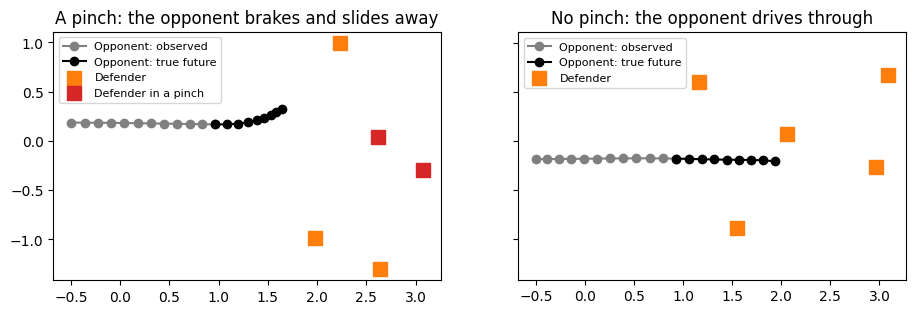

In [7]:
MAX_N_B = 6
PINCH_DIST = 0.9

def close_pairs(P):
    """Boolean matrix: which pairs of defenders are within PINCH_DIST of each other."""
    d = np.linalg.norm(P[:, None, :] - P[None, :, :], axis=2)
    return (d < PINCH_DIST) & ~np.eye(len(P), dtype=bool)

def generate_scene_b(rng, max_n=MAX_N_B):
    """Stationary defenders ahead of the opponent. A close pair triggers braking and a sideways slide."""
    total = T_HIST + M
    n = rng.integers(3, max_n + 1)
    want_pinch = rng.random() < 0.5

    def sample_layout():
        P = np.stack([rng.uniform(1.0, 3.2, n), rng.uniform(-1.4, 1.4, n)], axis=1)
        if want_pinch:                      # force one pair close together
            i = rng.integers(0, n)
            j = (i + 1 + rng.integers(0, n - 1)) % n
            angle = rng.uniform(0, 2 * np.pi)
            P[j] = P[i] + rng.uniform(0.3, 0.7) * np.array([np.cos(angle), np.sin(angle)])
        return P

    P = sample_layout()
    while close_pairs(P).any() != want_pinch:       # make sure the label really matches the layout
        P = sample_layout()

    pairs = close_pairs(P)
    in_pinch = np.zeros(n)                          # flags the two defenders that actually form the pinch
    midpoint = None
    if want_pinch:
        dists = np.where(pairs, np.linalg.norm(P[:, None] - P[None], axis=2), np.inf)
        i, j = np.unravel_index(np.argmin(dists), dists.shape)      # the closest pair is the one that triggers the behavior
        midpoint = (P[i] + P[j]) / 2
        in_pinch[[i, j]] = 1

    pos = np.array([-0.5, rng.uniform(-0.3, 0.3)])
    vel = np.array([rng.uniform(0.8, 1.4), 0.0])
    base_speed = rng.uniform(1.2, 1.8)
    side = 0.0 if midpoint is None else (1.0 if midpoint[1] < pos[1] else -1.0)

    opp = np.zeros((total, 2))
    defs = np.zeros((total, max_n, 2))
    present = np.zeros((total, max_n))
    for t in range(total):
        opp[t] = pos
        defs[t, :n] = P
        present[t, :n] = 1
        to_goal = np.array([10.0, 0.0]) - pos
        accel = (base_speed * to_goal / np.linalg.norm(to_goal) - vel) / 0.4
        for k in range(n):                          # weak repulsion from every individual defender
            away = pos - P[k]
            dist = np.linalg.norm(away) + 1e-6
            accel += 4.0 * np.exp(-dist / 0.35) * away / dist
        if midpoint is not None:                    # the pinch: brake and slide away from the pair
            near = 1 - np.linalg.norm(pos - midpoint) / 2.0
            if near > 0:
                accel += -9.0 * vel * near + np.array([0.0, side]) * 6.0 * near
        vel = vel + accel * DT
        pos = pos + vel * DT

    in_pinch_padded = np.zeros(max_n)
    in_pinch_padded[:n] = in_pinch
    return dict(opp=opp + rng.normal(0, NOISE, opp.shape), defs=defs + rng.normal(0, NOISE, defs.shape),
                present=present, in_pinch=in_pinch_padded, clean_opp=opp, midpoint=midpoint, layout=P)

train_b = make_dataset(generate_scene_b, 10000, seed=1, max_n=MAX_N_B)
test_b = make_dataset(generate_scene_b, 1000, seed=2, max_n=MAX_N_B)
has_pinch = test_b['in_pinch'].sum(1) > 0
print(f"Scene B test set: {has_pinch.float().mean():.0%} of scenes contain a pinch")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, want, title in zip(axes, [True, False], ["A pinch: the opponent brakes and slides away", "No pinch: the opponent drives through"]):
    rng_plot = np.random.default_rng(5)
    while True:
        s = generate_scene_b(rng_plot)
        if (s['midpoint'] is not None) == want and 4 <= int(s['present'][0].sum()) <= 5:
            break
    ax.plot(s['clean_opp'][:T_HIST, 0], s['clean_opp'][:T_HIST, 1], 'o-', color='gray', label='Opponent: observed')
    ax.plot(s['clean_opp'][T_HIST - 1:, 0], s['clean_opp'][T_HIST - 1:, 1], 'o-', color='black', label='Opponent: true future')
    P, flagged = s['layout'], s['in_pinch'][:len(s['layout'])] > 0
    ax.scatter(P[~flagged, 0], P[~flagged, 1], marker='s', s=90, color='tab:orange', label='Defender')
    if flagged.any():
        ax.scatter(P[flagged, 0], P[flagged, 1], marker='s', s=90, color='tab:red', label='Defender in a pinch')
    ax.set_title(title); ax.set_aspect('equal'); ax.legend(fontsize=8)
plt.show()

### Comparing Models on Scene B

Now the comparison. We have to be careful about fairness here, because a Transformer typically has more parameters than a small LSTM, and "the bigger model did better" would be a boring result. So we'll include two Social LSTMs: the one from `06b`, and a much larger one with more parameters than the Transformer. And since a single training run's result can move by a few thousandths from the random seed alone, every model gets three seeds, and we'll report the mean and the range. This cell takes a few minutes to run.

In [8]:
configs = {
    'Social LSTM (small)': lambda: SocialLSTM(hidden=64, nbr_dim=32),
    'Social LSTM (large)': lambda: SocialLSTM(hidden=192, nbr_dim=96),
    'Transformer': lambda: TrajectoryTransformer(),
}
seeds = [0, 1, 2]
results_b = {}
models_b = {}
for name, factory in configs.items():
    t0 = time.time()
    trained = [train_model(factory, train_b, seed=s) for s in seeds]
    scores = [ade(m, test_b) for m in trained]
    results_b[name] = dict(scores=scores, params=n_params(trained[0]), seconds=(time.time() - t0) / len(seeds))
    models_b[name] = trained

print(f"{'':22s} {'mean ADE':>9} {'range':>17} {'params':>9} {'train/seed':>11}")
print(f"{'Constant velocity':22s} {constant_velocity_ade(test_b):9.3f}")
for name, r in results_b.items():
    print(f"{name:22s} {np.mean(r['scores']):9.3f} {min(r['scores']):8.3f} - {max(r['scores']):.3f} {r['params']:9,} {r['seconds']:9.0f} s")

                        mean ADE             range    params  train/seed
Constant velocity          0.281
Social LSTM (small)        0.091    0.091 - 0.091    31,952        14 s
Social LSTM (large)        0.082    0.082 - 0.083   247,248        34 s
Transformer                0.075    0.074 - 0.076   106,256        68 s


The Transformer comes out ahead: a mean ADE of 0.075 versus 0.082 for the large Social LSTM and 0.091 for `06b`'s small one. The seed-to-seed ranges are tiny (about 0.001 to 0.002), so these gaps are well outside seed noise. That's an improvement of roughly 9% over an LSTM with 2.3x the parameters, and roughly 18% over the model from `06b`. All three are a big improvement over constant velocity's 0.281.

The edge is modest in absolute terms, a few thousandths of an ADE unit. Second, notice how much of the gap between the Transformer and `06b`'s model is just capacity. Simply making the LSTM bigger closed about half of it (0.091 to 0.082). That's why we ran the large LSTM, because comparing only against the small one would have overstated the case.

### Where Does the Transformer Win?

If the Transformer is doing something the Social LSTM can't, does its advantage concentrate in the scenes that actually contain a pinch? We split the test set both ways.

In [9]:
def ade_per_scene(model, data):
    with torch.no_grad():
        pred = model(data['opp'], data['nbr'], data['mask'])
    return (pred - data['future']).reshape(-1, M, 2).norm(dim=2).mean(dim=1)

print(f"{'':22s} {'pinch scenes':>13} {'no-pinch scenes':>16}")
for name, trained in models_b.items():
    per_scene = torch.stack([ade_per_scene(m, test_b) for m in trained]).mean(0)    # average over the 3 seeds
    print(f"{name:22s} {per_scene[has_pinch].mean():13.3f} {per_scene[~has_pinch].mean():16.3f}")

                        pinch scenes  no-pinch scenes
Social LSTM (small)            0.096            0.085
Social LSTM (large)            0.087            0.077


Transformer                    0.079            0.071


This is the check that tempers the result. If the Transformer were winning because it can reason about pairs of defenders, we'd expect its advantage to be concentrated in the pinch scenes. It isn't! It leads the large LSTM by about 9% on pinch scenes (0.079 vs. 0.087) and about 8% on scenes with no pinch (0.071 vs. 0.077), which is essentially the same margin.

So the Transformer is better on this data, but we can't claim it's better because of pairwise reasoning. The advantage looks more general. Attention handles a variable-size set of tokens flexibly, and both kinds of scene contain defenders whose layout affects the opponent. We designed Scene B to stress relational reasoning, but these results don't isolate it.

### Reading the Attention Weights

Attention weights are tempting to read as an explanation. If the model is detecting pinches, the opponent's final token should be attending heavily to the two defenders in the pinch. We can check that directly. For each scene with a pinch, we take the opponent's final-step token and measure what share of its attention (summed over all time steps) lands on the defenders in the pinch, versus what share you'd expect if it attended to defenders uniformly at random.

In [10]:
def attention_share_on_pinch(model, data):
    """Per layer: the share of the opponent-final-token's attention on pinch defenders (vs. the uniform-attention chance level)."""
    scene_idx = torch.nonzero(has_pinch).flatten()
    opp, nbr, mask, in_pinch = (data[k][scene_idx] for k in ('opp', 'nbr', 'mask', 'in_pinch'))
    B, N = len(scene_idx), nbr.shape[2]
    with torch.no_grad():
        tokens, padding = model.tokenize(opp, nbr, mask)
        shares = []
        for layer in model.encoder.layers:
            _, w = layer.self_attn(tokens, tokens, tokens, key_padding_mask=padding, need_weights=True, average_attn_weights=True)
            on_defenders = w[:, T_HIST - 1, T_HIST:].reshape(B, T_HIST, N).sum(1)      # (B, N): per defender, summed over time
            on_defenders = on_defenders / on_defenders.sum(1, keepdim=True)            # renormalize across defenders only
            shares.append((on_defenders * in_pinch).sum(1).mean().item())
            tokens = layer(tokens, src_key_padding_mask=padding)
    chance = (in_pinch.sum(1) / mask[:, -1].sum(1)).mean().item()
    return shares, chance

shares, chance = attention_share_on_pinch(models_b['Transformer'][0], test_b)
for i, s in enumerate(shares):
    print(f"Layer {i}: {s:.1%} of attention on pinch defenders   (uniform-attention chance: {chance:.1%})")

Layer 0: 44.1% of attention on pinch defenders   (uniform-attention chance: 48.0%)
Layer 1: 48.6% of attention on pinch defenders   (uniform-attention chance: 48.0%)


The answer is no, at least not in a way you can read off the weights. The opponent's final token puts 44% of its attention on the pinch defenders in the first layer and 49% in the second, against a chance level of 48%. It is indistinguishable from uniform.

That doesn't prove the model is ignoring pinches, because the weights from one token in one layer are only one route information can take. The defender tokens can attend to each other, detect the pair there, and pass the result along, and none of that shows up in this measurement. But it's a good concrete reminder that attention weights are not explanations. A model can be right for reasons its attention maps don't reveal (see the Jain & Wallace reference below).

## What It Costs

Accuracy isn't the only axis. `06b` noted that attention's cost grows quickly with sequence length, which is a real constraint on edge hardware (see `edge_computing_primer`). With one token per agent per step, self-attention compares all $12 \times (1 + N)$ tokens against each other, so the cost grows with the *square* of the token count. Let's measure the inference cost of one scene on this machine's CPU, as a robot would run it.

In [11]:
def latency_ms(model, data, repeats=200):
    one = {k: v[:1] for k, v in data.items()}
    with torch.no_grad():
        for _ in range(20):                       # warm-up
            model(one['opp'], one['nbr'], one['mask'])
        t0 = time.perf_counter()
        for _ in range(repeats):
            model(one['opp'], one['nbr'], one['mask'])
    return (time.perf_counter() - t0) / repeats * 1000

n_tokens = T_HIST * (1 + MAX_N_B)
print(f"Tokens per scene: {n_tokens}  (attention matrix: {n_tokens} x {n_tokens} = {n_tokens ** 2:,} scores per head per layer)\n")
for name in configs:
    m = models_b[name][0]
    print(f"{name:22s} {latency_ms(m, test_b):6.2f} ms per scene   ({n_params(m):,} params)")

Tokens per scene: 84  (attention matrix: 84 x 84 = 7,056 scores per head per layer)

Social LSTM (small)      0.21 ms per scene   (31,952 params)


Social LSTM (large)      0.28 ms per scene   (247,248 params)


Transformer              0.52 ms per scene   (106,256 params)


Everything here is fast in absolute terms. All three run in well under a millisecond per scene. But the Transformer is about 2x slower than the larger LSTM per scene despite having fewer than half its parameters, and it trained roughly 5x slower than the small LSTM (about 68 seconds per seed vs. 14). Parameter count and speed aren't the same thing for attention.

The part to watch is the scaling. Our scene has 84 tokens. A realistic one, say 20 agents over 50 steps, has 1,000 or so tokens, and since the attention matrix is tokens x tokens, that's roughly 150 times as many scores to compute per head per layer. The LSTM's cost grows only linearly with the number of steps. That's the practical tension behind the edge-hardware point in `genai_architecture_primer`, and it's why real systems restrict attention to nearby agents or a short window.

## The Limits of This Approach

- **The result is modest, and it's synthetic.** On a scene built to favor it, the Transformer beat a larger LSTM by roughly 9% of ADE, and on the scene `06b`'s Social LSTM was designed for, it only tied. Real match data has noise, tracker ID swaps, and strategies nobody wrote down. Nothing here substitutes for evaluating on real film.
- **We couldn't isolate *why* it won.** The advantage was the same size on scenes with and without a pinch, and the attention weights were at chance. "Better at set-structured inputs" is a fair summary. "Learned to reason about pairs" is a story we didn't earn.
- **Transformers are data-hungry.** They have fewer built-in assumptions than an LSTM (an LSTM *knows* time is ordered and recent steps matter; a Transformer has to learn it from positional embeddings). With 8,000 to 10,000 training scenes, that's a handicap, and a plausible reason it didn't pull ahead on Scene A. Real trajectory-forecasting systems train on far more data, often with additional tricks.
- **Attention weights aren't explanations.** We checked directly, and the weights didn't tell us what the model was doing, even where the model was clearly getting something right.
- **Still just one answer.** Like everything in `06` and `06b`, this model outputs a single path, so it has the mode-averaging problem from `07` whenever the future is genuinely ambiguous. Real Transformer-based predictors (Wayformer, MTR, and similar) almost always put a multi-hypothesis head on top, which is exactly what `07` builds.
- **A real predictor has more inputs.** Production systems also feed in the map (lanes, field boundaries), agent size and type, and more history than 12 steps. Treating everything as tokens is what makes those additions easy to bolt on, and it's a large part of why Transformers became the default.

## Try It Yourself

**1. Does more data give the Transformer an edge on Scene A?** The Transformer only *tied* the Social LSTM on Scene A, and we suggested limited data as one reason. Test it. Generate `train_a_big = make_dataset(generate_scene_a, 40000, seed=1, max_n=MAX_N_A)` (this takes a while), retrain both models on it, and compare. Does the Transformer pull ahead, or do they stay tied? Write one sentence on what that tells you about whether data was the limiting factor.

**2. How much does the positional embedding matter?** Remove `self.time_pos` from `TrajectoryTransformer.tokenize` (so the model can't tell which step a token is from) and retrain on Scene B. Does it get worse, and by how much? Why might the answer be *smaller than you'd expect* for this particular scene, given that the defenders are stationary?

In [12]:
# TODO 1: build train_a_big (40,000 scenes), retrain SocialLSTM and TrajectoryTransformer on it, compare test ADE on test_a

# TODO 2: subclass or edit TrajectoryTransformer to drop the time_pos embedding, retrain on train_b, compare against the full model

## Resources

- Vaswani, A. et al. (2017). "Attention Is All You Need." *NeurIPS 2017*. The original Transformer paper, already the subject of `genai_architecture_primer/03` (paper).
- Giuliari, F. et al. (2020). "Transformer Networks for Trajectory Forecasting." *ICPR 2021*. One of the earliest direct applications of a plain Transformer to pedestrian trajectories, close in spirit to this notebook's model (paper).
- Yuan, Y. et al. (2021). "AgentFormer: Agent-Aware Transformers for Socio-Temporal Multi-Agent Forecasting." *ICCV 2021*. Attention across both time and agents at once, the idea behind this notebook's agent-time tokens (paper).
- Nayakanti, N. et al. (2023). "Wayformer: Motion Forecasting via Simple & Efficient Attention Networks." *ICRA 2023*. A production-scale Transformer trajectory predictor with multiple output hypotheses, the combination of this notebook and `07` (paper).
- Jain, S. & Wallace, B. (2019). "Attention is not Explanation." *NAACL 2019*. The standard reference for the caution in the "Reading the Attention Weights" section (paper).
- `genai_architecture_primer/02-attention-mechanism.ipynb` and `03-transformer-block-and-history.ipynb` - the from-scratch attention and Transformer block this notebook builds on.